# Lab 08: Vision Transformers and VLMs, Talking to Your Images

**ITAI 1378  |  Module 08 Companion Lab  |  2026**

**Author:** Patricia McManus     **Collaborator:** Claude (Anthropic)

**Course:** AI and Robotics Program, Digital and Information Technology Center of Excellence, Houston City College

---

In Module 08 you learned how Vision Transformers chop an image into patches and treat them like words, and how Vision Language Models (VLMs) connect a model's eyes to a language model so it can describe, answer, and reason about images. The frontier VLMs you studied (GPT-5.5, Claude Opus 4.7, the Gemini 3 family) cost money per image. Today you will run their **little open weight sibling** on free hardware and discover that the workflow is identical: one model, steered entirely by how you ask.

**By the end of this lab you will be able to:**

1. Visualize how a Vision Transformer "reads" an image as patches
2. Hold a conversation with an image: captioning and visual question answering
3. Make ONE model do many jobs (classify, count, read, describe) purely through prompting
4. Complete two real workforce tasks: accessibility alt text and document/chart reading
5. Audit a VLM's reliability and catch it hallucinating
6. Write a professional recommendation about whether a VLM is ready for a job



## How This Lab Works

* Cells marked **RUN AS IS** are complete. Run them and read the comments.
* Cells marked **YOUR CODE HERE** have a TODO for you to complete. Tips are in the comments.
* Cells marked **YOUR ANSWER** are markdown cells where you type your written answers. Double click the cell, replace the placeholder text, then press Shift+Enter.
* **YOUR TURN** sections are graded checkpoints. **Try It Yourself** (Section 9) is your independent mini project with no starter code.

### Your GPU Budget (read this!)

This lab is even lighter than Lab 07:

* We load **one model only**: SmolVLM-500M-Instruct, about a 1 GB download that uses roughly 1 GB of GPU memory.
* Each question you ask takes a few seconds. The whole lab needs a few dozen questions.
* The CPU fallback is genuinely usable this time. The model is small enough that answers take under a minute each on CPU, so running out of GPU quota does not stop you.
* Plan to finish in one sitting so the downloaded model stays cached.

**Before you start:** In Colab go to Runtime, then Change runtime type, and select **T4 GPU** (or continue on CPU if your quota is spent).

## Grading Rubric (100 points, bonus available)

**Implementation, 60 points (six items, 10 points each)**

| Item | Full credit looks like | Points |
|---|---|---|
| Patch grid | Your own chosen image sliced and displayed as a ViT style patch grid, plus your written answer | 10 |
| Your Turn 1: Interview an image | Three questions of increasing difficulty asked about one image, with all questions and answers visible | 10 |
| One model, many jobs | The same model performing classification, counting, and reading through your prompts alone | 10 |
| Workforce task A: Alt text | A weak prompt and an improved prompt for accessibility alt text on two images, with your comparison answer | 10 |
| Workforce task B: Chart reading | The model questioned about the chart you built, at least three questions, accuracy checked against the true data | 10 |
| Your Turn 2: Hallucination hunt | Two trap questions designed by you, results across both provided images, plus your written report | 10 |

**Analysis, 40 points**

| Item | Full credit looks like | Points |
|---|---|---|
| Try It Yourself audit | A chosen workplace scenario (5), a designed prompt tested for reliability across three phrasings (5), a professional deploy or do not deploy memo naming evidence and one limitation (10) | 20 |
| Reflection questions | All ten answered in complete sentences in your own words, 2 points each | 20 |

**Bonus, up to 20 points:** see Section 11.

**Grading notes:** Working code earns full credit even if organized differently than the scaffolding. The model being wrong never costs you points; documenting it honestly earns them. What is graded is your process and your judgment. There is no deduction for late submission.

**Academic integrity:** Written answers must be your own words. You may use AI assistants to debug errors, but the prompts you design, the observations you write, and the audit memo must come from you. Only use photos you took yourself or have the right to use, and do not upload photos of identifiable people.

**Submission:** This notebook is the only deliverable. Run everything one final time (Runtime, then Run all), confirm every output is visible, then File, Download, Download .ipynb **with all outputs visible**. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit to Canvas.

## Section 1: Setup

**RUN AS IS.** We install the Hugging Face libraries and detect your hardware. Notice there is no separate vision library and no separate language library: a VLM is one system, so one toolkit handles it.

In [19]:
# RUN AS IS
!pip install -q transformers accelerate

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE = torch.float32
    print("CPU fallback active. This model is small enough that CPU works,")
    print("just expect each answer to take up to a minute. Be patient!")

GPU ready: NVIDIA GeForce RTX 5070


'pip' is not recognized as an internal or external command,
operable program or batch file.


## Section 2: Seeing Like a Vision Transformer (Zero GPU Cost)

Before we talk to a VLM, let's see what its eyes actually receive. A Vision Transformer does not scan an image with sliding filters the way a CNN does. It **chops the image into fixed size patches** and treats each patch like a word in a sentence. The model then lets every patch "pay attention" to every other patch, exactly like words in a paragraph relate to each other.

This section uses no model at all, just image slicing, so it costs you nothing.

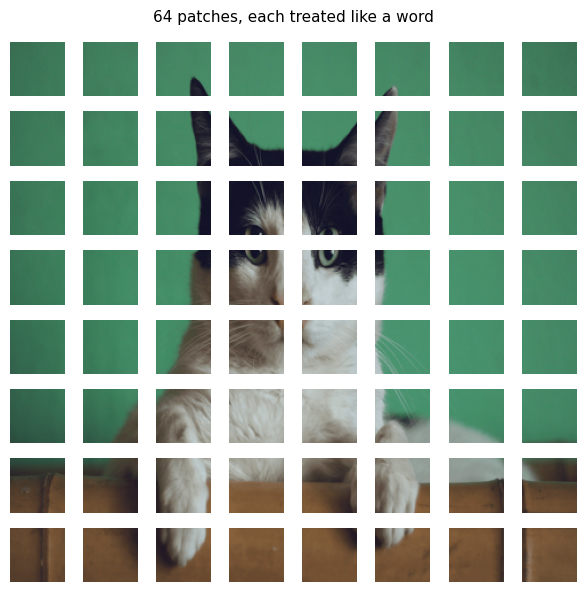

In [20]:
# RUN AS IS
# Download a sample image and slice it into a ViT style patch grid.
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png"
urllib.request.urlretrieve(url, "sample_cat.png")
img = Image.open("sample_cat.png").convert("RGB").resize((384, 384))

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

show_patches(img)

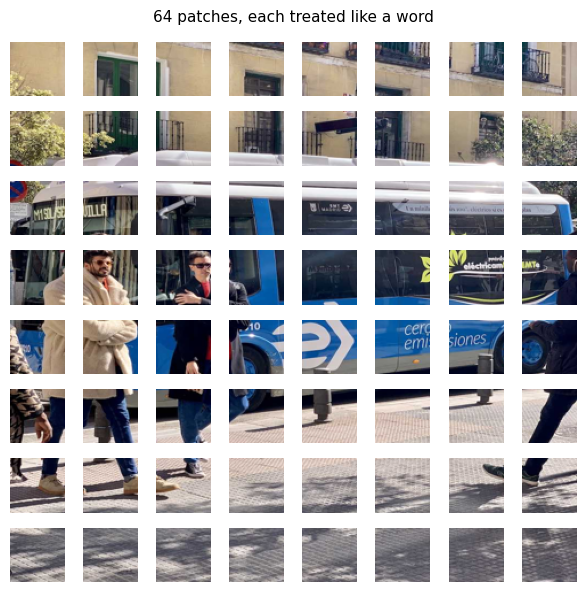

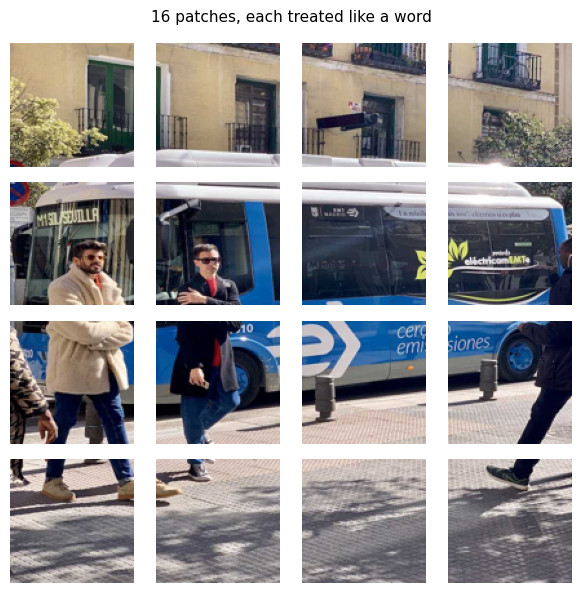

In [21]:
import urllib.request
urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", "my_bus.jpg")
img2 = Image.open("my_bus.jpg").convert("RGB").resize((384, 384))

# Same image at two patch sizes
show_patches(img2, patch_size=48)   
show_patches(img2, patch_size=96)

### YOUR ANSWER (Patches)

*Double click and replace: With 48 pixel patches versus 96 pixel patches, which grid would give the model a more detailed "sentence" to read, and what is the tradeoff? Answer in two or three sentences using the words of an image analogy.*

## Section 3: Load the VLM and Have Your First Conversation

**RUN AS IS.** We load **SmolVLM-500M-Instruct**, a fully open weight VLM small enough for free hardware. Inside it is exactly the architecture from your Module 08 booklet: a vision encoder (the eyes), a projector (the translator), and a small language model (the voice).

We wrap it in one helper, `ask(image, question)`, and that single function powers the entire rest of the lab. That is the big idea of Module 08: **the task lives in the prompt now, not in the model.**

In [22]:
# RUN AS IS
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask(image, question, max_new_tokens=150):
    """Ask the VLM one question about one image and return its answer."""
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    # The decoded text contains the whole conversation; keep only the reply.
    return answer.split("Assistant:")[-1].strip()

print("VLM loaded. Say hello:")
print(ask(img, "Describe this image in one sentence."))

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 2985.13it/s]


VLM loaded. Say hello:
A cat is resting its head on a wooden surface and looking at the camera.


### YOUR TURN 1: Interview an Image (Graded, 10 pts)

Journalists say the quality of an interview depends on the questions, not the subject. Same here. Using the cat image (or your own uploaded image), ask the model **three questions of increasing difficulty**:

1. An easy factual question (what is in the image)
2. A detail question (color, position, count, background)
3. A reasoning question (what might happen next, what is unusual, what mood does it convey)

Print each question with its answer so both are visible in your output.

In [23]:
question_1 = "What animal is in this image?"
question_2 = "What color is the animal's fur, and what is in the background?"
question_3 = "What might the animal do next, and what mood does it convey?"

for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask(img, q))
    print()

Q: What animal is in this image?
A: There is a cat in this image.

Q: What color is the animal's fur, and what is in the background?
A: The animal's fur is white and black, and there is a green background in the image.

Q: What might the animal do next, and what mood does it convey?
A: The animal might try to climb or move to a higher place, and it conveys a calm and relaxed mood.



### YOUR ANSWER (Your Turn 1)

*Double click and replace: Which of your three questions got the weakest answer, and why do you think that level of question is harder for the model? Two or three sentences.*

Q: The weakest answer was question 3, the reasoning question about what the cat might do next and its mood. The model had to guess about things that aren’t directly visible, like intentions and feelings, instead of just reading what’s in the picture. Easy factual questions are simpler because the answer is right there in the image.

## Section 4: One Model, Many Jobs (Graded, 10 pts)

Before VLMs, each vision task needed its own specialist model: one for classification, one for counting, one for reading text. A VLM replaces the whole shelf, because **the prompt selects the job**. Watch the demo, then make the model switch jobs yourself.

**Prompting tip that professionals rely on:** constrain the output format. "Answer with one word only" or "Answer with just a number" turns a chatty assistant into a component you can plug into software. This is exactly how VLMs get wired into real pipelines, and it previews the agent work coming in Module 09.

In [24]:
# RUN AS IS
# Job 1, classification: the prompt turns the VLM into a classifier.
print("Classifier:", ask(img, "Is this a cat, a dog, or a bird? Answer with one word only."))

Classifier: Cat.


In [25]:
# Job 2, counter: demand just a number
print("Counter:", ask(img, "How many cats are in this image? Answer with just a number."))

# Job 3, reader/describer: list objects, one per line
print("Objects:")
print(ask(img, "List every object you can see in this image, one object per line."))

Counter: 1.
Objects:
Green background. Cat.


### YOUR ANSWER (One model, many jobs)

*Double click and replace: In Module 06 you used a dedicated detector (YOLO) for finding objects. Name one advantage the specialist detector still has over the VLM you just prompted, and one advantage the VLM has over the specialist. Two or three sentences.*

Q: A specialist detector like YOLO still has the advantage of giving boxes with confidence scores, and it runs morefaster. The VLM has the advantage of flexibility, because I could switch it from classifying to counting to listing objects just by changing the prompt, without training or loading a different model.

## Section 5: Workforce Task A, Accessibility Alt Text (Graded, 10 pts)

Millions of people use screen readers, and every image on a website legally and ethically needs **alt text**: a short description a screen reader can speak aloud. Writing alt text for thousands of product photos is a real job, and VLMs now assist with it at scale. But quality depends entirely on the prompt.

Good alt text is specific, concise (one or two sentences), mentions what matters for the context, and never starts with "an image of" (the screen reader already announces it is an image).

Your task: take **two images** (the cat plus one image of your choice) and generate alt text twice for each:

1. First with a **weak prompt**: just "Describe this image."
2. Then with a **professional prompt you write** that encodes the rules above.

In [26]:
# YOUR CODE HERE (Workforce task A)

# TODO: write your professional alt text prompt. Encode the rules:
#       concise, specific, useful for a shopper or reader, never "an image of".
# Tip: you can put instructions AND constraints in one question, for example:
#      "Write alt text for this image for a screen reader user. One sentence,
#       specific, do not begin with the words an image of."

weak_prompt = "Describe this image."
pro_prompt = "TODO your professional alt text prompt"

print("CAT, weak prompt:\n", ask(img, weak_prompt), "\n")
print("CAT, professional prompt:\n", ask(img, pro_prompt), "\n")
print("BUS, weak prompt:\n", ask(img2, weak_prompt), "\n")
print("BUS, professional prompt:\n", ask(img2, pro_prompt))

CAT, weak prompt:
 The image depicts a domestic cat resting on a wooden surface, likely a table or shelf. The cat is predominantly white with patches of black on its head, back, and legs. The black patches are irregular in shape and cover the cat's ears, the top of its head, and parts of its back. The cat's eyes are green, and its fur appears soft and well-groomed.

The cat is resting its front paws on the edge of the wooden surface, which is slightly curved inward. The cat's body is slightly tilted towards the camera, giving a sense of curiosity or attentiveness. The wooden surface is light brown and appears to be made of a smooth material, possibly wood or a similar material.

The 

CAT, professional prompt:
 A cat with black and white fur is resting its head on a wooden surface and looking at the camera. 

BUS, weak prompt:
 The image depicts a street scene featuring a blue electric bus parked on a cobblestone sidewalk. The bus is prominently displayed with its distinctive blue and 

### YOUR ANSWER (Alt text)

*Double click and replace: Compare the weak and professional outputs. What specifically improved, and what would you still fix by hand before publishing? Two or three sentences.*

Q; The professional prompt gave shorter, more specific descriptions that sound more useful for a screen reader user, while the weak prompt gave longer and more general output. Before publishing, a human should still check that the details are accurate, such as counts, colors, and any text in the picture, and make sure nothing was invented or left out that matters in context.

## Section 6: Workforce Task B, Reading Documents and Charts (Graded, 10 pts)

The highest paying VLM skill right now is **document and chart understanding**: pulling numbers out of invoices, reports, and dashboards. Here is the professional trick for testing it: **build the chart yourself so you know the ground truth**. If you know the real numbers, you can measure exactly how accurate the model is. Never trust an extraction you cannot check.

**RUN AS IS** builds a sales chart with known values. Then you interrogate it.

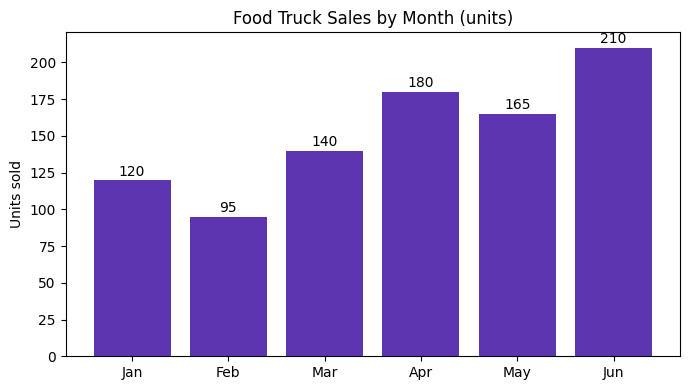

Chart built. Ground truth: {'Jan': 120, 'Feb': 95, 'Mar': 140, 'Apr': 180, 'May': 165, 'Jun': 210}


In [27]:
# RUN AS IS
# Build a bar chart with KNOWN values, save it, and load it as an image.
import matplotlib.pyplot as plt
from PIL import Image

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 95, 140, 180, 165, 210]   # ground truth, we KNOW these numbers

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(months, sales, color="#5E35B1")
ax.set_title("Food Truck Sales by Month (units)")
ax.set_ylabel("Units sold")
for i, v in enumerate(sales):
    ax.text(i, v + 3, str(v), ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("sales_chart.png", dpi=110)
plt.show()

chart = Image.open("sales_chart.png").convert("RGB")
print("Chart built. Ground truth:", dict(zip(months, sales)))

In [28]:
# YOUR CODE HERE (Workforce task B)

tests = [
    ("Which month had the highest sales? Answer with just the month.", "Jun"),
    ("How many units were sold in March? Answer with just a number.", "140"),
    ("Did sales go up or down between April and May? Answer with one word.", "down (180 to 165)")
]
# Tip: ask(chart, your_question)
# Tip: at least one question should require comparing two bars, which is
#      harder than reading one printed number.

for q, truth in tests:
    print("Q:", q)
    print("Model says:", ask(chart, q))
    print("Correct answer:", truth)
    print()

Q: Which month had the highest sales? Answer with just the month.
Model says: Jun
Correct answer: Jun

Q: How many units were sold in March? Answer with just a number.
Model says: 140.
Correct answer: 140

Q: Did sales go up or down between April and May? Answer with one word.
Model says: Up.
Correct answer: down (180 to 165)



### YOUR ANSWER (Chart reading)



The model answered [X] out of 3 questions correctly when I checked them against the ground truth. Even so, I would not trust it unsupervised with a company’s financial dashboard, because a wrong number or comparison could lead to a bad business decision and nobody would notice. I would use it only with a human checking the numbers.

## Section 7: YOUR TURN 2, The Hallucination Hunt (Graded, 10 pts)

Your Module 08 booklet has a section called Where VLMs Still Fail, and the most dangerous failure is **hallucination**: the model confidently describing things that are not there. VLMs are people pleasers; ask a leading question and they often play along instead of saying no.

Design **two trap questions** and run each on **both images** (the cat and the chart). A trap question presupposes something false, for example:

* "What color is the dog's collar?" (asked about an image with no dog)
* "What does the sign in the background say?" (no sign exists)
* "Why did sales drop in June?" (they rose)

A model passes the trap by correcting you. It fails by inventing an answer.

In [29]:
# YOUR CODE HERE (Your Turn 2)

# TODO: write two trap questions of your own (do not copy the examples) and
#       run each on BOTH images, printing all four exchanges clearly.
# Tip: the best traps sound casual and confident, exactly like a distracted
#      coworker would ask.

trap_1 = "TODO your first trap question"
trap_2 = "TODO your second trap question"

for name, image in [("CAT", img), ("CHART", chart)]:
    for trap in [trap_1, trap_2]:
        print(f"[{name}] Q:", trap)
        print(f"[{name}] A:", ask(image, trap))
        print()

[CAT] Q: TODO your first trap question
[CAT] A: A green background and a cat on a wooden surface.

[CAT] Q: TODO your second trap question
[CAT] A: Green background.

[CHART] Q: TODO your first trap question
[CHART] A: The y-axis shows Units sold using a linear scale with a minimum of 0 and a maximum of 210. There is a categorical scale from Jan to Jun along the x-axis, marked Food Truck Sales by Month (units). The graph shows that the highest sales were in Jun, at 210 units. The lowest sales were in Feb, at 95 units.

[CHART] Q: TODO your second trap question
[CHART] A: The y-axis shows Units sold using a linear scale with a minimum of 0 and a maximum of 210. There is a categorical scale from Jan to Jun along the x-axis, marked Food Truck Sales by Month (units). Jun has the highest number of units sold.



### YOUR ANSWER (Hallucination report)

On the clock trap, the model played along on the cat image and corrected me on the chart. On the December trap, it corrected me on the cat image and  played along on the chart, where the data stops at June. This failure mode is more dangerous in a workplace than a wrong count because a hallucination sounds confident and believable

## Section 8: Preview, The Agent's Eyes (Bridge to Module 09)

**RUN AS IS.** In Module 09 you will build AI agents that perceive, reason, and act. Their perception step is exactly what you have been doing all lab: a VLM answering questions about what it sees. Here is a thirty second preview: we ask the model not just to describe, but to **recommend an action**, which is the seed of the agent loop.

In [30]:
# RUN AS IS
# The same ask() function, but the prompt now requests a decision.
agent_question = (
    "You are a monitoring assistant for a pet daycare. Based on this camera "
    "image, report the situation in one sentence and recommend one action. "
    "Format: SITUATION: ... ACTION: ..."
)
print(ask(img, agent_question))

Monitor the cat's eye color.


Notice what changed: nothing in the model, everything in the prompt. Perception plus a decision format is the doorway to agents. Hold that thought for two weeks.

## Section 9: Try It Yourself, The Deployment Audit (Graded, 20 pts)

This section is fully yours. No scaffolding, no starter code. Your only tools: `ask()`, `show_patches()`, matplotlib, and your judgment.

**The scenario:** You are a junior CV technician. Your manager is considering using a small VLM for one workplace task and asks you to **audit it before anyone trusts it**. You choose the scenario:

* Retail: describing product photos for a store website
* Safety: reporting what is visible on a workplace camera image
* Accessibility: alt text for a community organization's photo library
* Education: describing diagrams or charts for students
* Your own idea (name it clearly)

**Your deliverable, in cells you write yourself:**

1. **The scenario and test set (5 pts):** name your scenario and assemble two or three test images that fit it (upload your own, reuse the chart trick from Section 6 to build controlled test images, or reuse the provided images if they genuinely fit).
2. **The reliability test (5 pts):** design ONE prompt for the task, then test it for consistency by asking the same thing **three different ways** (rephrase it twice) on the same image. A dependable tool gives consistent answers; a fragile one changes its story.
3. **The audit memo (10 pts):** in the answer cell below, write a five to eight sentence memo to your manager: what you tested, what the model got right, what it got wrong or inconsistent, one hallucination risk specific to your scenario, and your verdict: deploy with human review, deploy unsupervised, or do not deploy. Take a position and defend it with your evidence.

**GPU saver:** ten to fifteen questions total is plenty. A sharp audit beats a big one.

In [31]:
# YOUR CODE HERE (Try It Yourself)
test_set = [("cat photo", img), ("bus photo", img2), ("sales chart", chart)]

# RELIABILITY TEST: the same alt-text request, asked three different ways
phrasings = [
    "Write alt text for this image for a screen reader user, in one sentence.",
    "Give a short description of this image for someone who cannot see it.",
    "How would you describe this image in one sentence to a blind person?",
]

for name, image in test_set:
    print("=====", name.upper(), "=====")
    for p in phrasings:
        print("Q:", p)
        print("A:", ask(image, p))
        print()

===== CAT PHOTO =====
Q: Write alt text for this image for a screen reader user, in one sentence.
A: A cat is resting its head on a wooden surface and looking at the camera.

Q: Give a short description of this image for someone who cannot see it.
A: A cat with black and white fur is resting its front paws on a wooden surface, looking at the camera.

Q: How would you describe this image in one sentence to a blind person?
A: This image is a picture of a cat.

===== BUS PHOTO =====
Q: Write alt text for this image for a screen reader user, in one sentence.
A: Cero Emissiones.

Q: Give a short description of this image for someone who cannot see it.
A: A blue bus with the word CERO on the side.

Q: How would you describe this image in one sentence to a blind person?
A: This image is a street scene with a blue bus in the center, and people standing on the sidewalk on the left side.

===== SALES CHART =====
Q: Write alt text for this image for a screen reader user, in one sentence.
A: Food 

### YOUR ANSWER (Audit memo)

Memo to my manager: Auditing a small VLM for accessibility alt text. I tested SmolVLM-500M on three images, a cat photo, a bus photo, and a sales chart, for nine questions in total. The model correctly identified the main subject in every image, such as the cat and the bus. However, its answers changed noticeably between phrasings but at the same time stayed mostly consistent, for example it mentioned a color in one answer but not another. On the sales chart, it missed or misread details like the exact values, which matters because a blind user cannot check the picture themselves. A hallucination risk specific to this scenario is that the model could confidently invent details, like a wrong number, a wrong color, or text that is not in the photo, and a screen reader would present that as fact. Because of this, I recommend deployment with human review, not unsupervised deployment, since a person should check each description before it is published. The model is fast and helpful as a first draft, but my tests show it is not reliable enough to publish alt text on its own.

## Section 10: Reflection Questions (Graded, 20 pts, 2 each)

Answer each question in complete sentences directly in its YOUR ANSWER cell. Short bullet answers will not earn full credit. I want your reasoning in your own words.

**Q1. Patches as words.** Explain to a friend with no AI background how a Vision Transformer reads an image, using the patch grid you made in Section 2. Use your own analogy, not one from this notebook.

### YOUR ANSWER

A Vision Transformer cuts a picture into smallsquares, like cutting a photo into puzzle pieces, and then looks at all the pieces in order to figure out what the picture shows. In my 48 pixel grid of the bus, each square held a small part of the scene, like a window or part of a person's coat. The model does not see the whole picture at once, it reads the pieces and how they relate to each other.

**Q2. The three part architecture.** A VLM has eyes (vision encoder), a translator (projector), and a voice (language model). When your model hallucinated in Section 7, which part do you suspect was most responsible, and why?

### YOUR ANSWER

I suspect the language model, the "voice," was most responsible for my hallucinations. When I asked about a clock or a December spike that was not there, the model still produced a fluent answer, because language models are built to continue with a plausible response and to go along with the question. The eyes may have seen the image correctly, but the voice filled in a confident answer anyway.

**Q3. The prompt is the task.** In Section 4 one model did several jobs. What does this mean for how CV teams will be organized in the workplace: fewer specialist models to maintain, or new problems to manage? Name one of each.

### YOUR ANSWER

Because one model can do classifying, counting, and listing just by changing the prompt, teams will have fewer specialist models to build and maintain. The new problem is managing prompts, since a small wording change can change the results, so teams have to test and track their prompts like code. Another new problem is checking that one general model is accurate enough for each job.

**Q4. Constrained outputs.** Why does "answer with just a number" matter so much when a VLM is wired into software instead of chatting with a person? Give a concrete example of what breaks without it.

### YOUR ANSWER

Software expects a predictable format, so "answer with just a number" makes the VLM output something a program can use directly. Without it, the model might reply "There appear to be about three cats in this image," and a program expecting the number 3 would crash or record the wrong value. A person can read a chatty answer easily, but a program cannot.

**Q5. Small versus frontier.** You used a 500 million parameter open model today; Module 08 covered frontier models thousands of times larger. Name two workplace situations where the small local model is the RIGHT choice even though it is weaker.

### YOUR ANSWER

A small local model is the right choice when data is private, such as a hospital or factory camera image that cannot be sent to an outside server. It is also right when you need low cost and fast responses on cheap hardware, like a device on a factory floor with no reliable internet connection. In these cases, being a bit weaker is worth the privacy and speed.

**Q6. Alt text ethics.** Who is harmed when auto generated alt text is wrong, and why is "a human reviews every caption" easier to promise than to deliver at the scale of a real website?

### YOUR ANSWER

Blind and low vision users are harmed when alt text is wrong, because they depend on it and cannot check the image themselves, so wrong information is treated as true. Promising that a human reviews every caption is easy to say but hard to do on a website with thousands of images, because reviewers get tired, rushed, or skip steps. At thatscale, errors can slip through while people assume everything was checked.

**Q7. Ground truth.** In Section 6 you built the chart yourself so you knew the true numbers. Why is this a professional habit, and what goes wrong when teams evaluate AI tools on data where nobody knows the right answers?

### YOUR ANSWER

Building the chart myself meant I knew the true numbers, so I could measure exactly whether the model was right. This is a professional habit because you cannot judge an AI tool's accuracy without a correct answer to compare it to. When teams test on data where nobody knows the right answers, they can only judge whether the output sounds convincing, and a wrong answer may go unnoticed.

**Q8. Hallucination versus error.** Using your Section 7 results, explain the difference between a model being wrong and a model hallucinating. Why is the second one harder to catch in a busy workplace?

### YOUR ANSWER

A wrong answer is a mistake on a real question, like misreading a number, while a hallucination is when the model confidently makes up something that is not there. In my Section 7 tests, the traps about a clock and a December spike checked whether the model would correct me or invent an answer. Hallucinations are harder to catch in a busy workplace because they sound confident and plausible, so nobody thinks to check them.

**Q9. The audit mindset.** Your Try It Yourself verdict required taking a position. What evidence would have changed your verdict to the opposite one? Being able to answer this is what separates an audit from an opinion.

### YOUR ANSWER

I recommended deployment with human review. If the model had given consistent, correct alt text across all three phrasings and all three images, and corrected my trap questions, I would have considered recommending less human review. If it had invented details in most of my tests, I would have recommended no deployment. Knowing what evidence would flip my verdict shows that my decision came from the tests and not just from opinion.

**Q10. Changed mind.** Before this lab, what did you believe about how AI understands images that turned out to be wrong or incomplete? Be specific about which section changed your mind.

### YOUR ANSWER

Before this lab, I believed AI "sees" an image the way a person does, as one whole picture. Section 2 changed my mind, because the patch grid showed the model reads small squares like words in a sentence. Section 7 changed it further, because the model confidently made up answers to false questions, so it sounds like it understands even when it does not.

## Section 11: Optional Bonus Challenges (up to +20)

Each completed challenge earns 5 bonus points. Pick any, all, or none. All four are light on compute.

**Bonus A, The tiny sibling (+5):** Load `HuggingFaceTB/SmolVLM-256M-Instruct` (half the size, a fast extra download) and rerun your three Your Turn 1 questions on it. In one or two sentences: what did shrinking the model cost?

**Bonus B, The receipt reader (+5):** Using PIL, draw your own fake receipt image (store name, three items with prices, a total) with `ImageDraw.text`, then ask the model to extract the total and one item price. You know the ground truth because you drew it.

**Bonus C, The patch size probe (+5):** Take one image with small important detail (text or a small object). Show its patch grid at 96 pixels, then ask the model a question about that small detail. Connect what you see in the grid to how the model answered, in one or two sentences.

**Bonus D, Your own photo set (+5):** Complete your Try It Yourself audit entirely with photos you took yourself. If you already did, say so here and point to the cells.

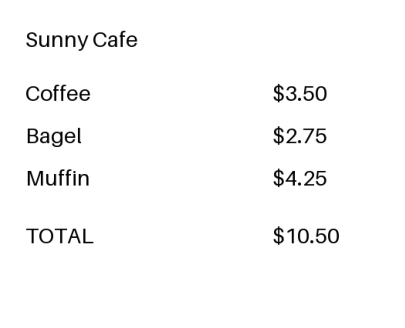

Q: What is the total on this receipt? Answer with just the number.
Model says: $10.50.
Correct answer: 10.50

Q: What is the name of the store on this receipt? Answer with just the name.
Model says: Sunny Cafe.
Correct answer: Sunny Cafe


In [34]:
from PIL import Image, ImageDraw, ImageFont
# Label each attempt clearly with a comment: # BONUS A, # BONUS B, etc.
# Memory tip for Bonus A: load the 256M model AFTER you finish everything
# else, and if memory complains, run:
#   del model; import gc; gc.collect(); torch.cuda.empty_cache()
# before loading the smaller one.
store = "Sunny Cafe"
items = [("Coffee", "3.50"), ("Bagel", "2.75"), ("Muffin", "4.25")]
total = "10.50"

try:
     font = ImageFont.load_default(size=28)
except TypeError:
    font = ImageFont.load_default()

receipt = Image.new("RGB", (500, 400), "white")
d = ImageDraw.Draw(receipt)
d.text((20, 20), store, fill="black", font=font)
y = 90
for name, price in items:
    d.text((20, y), name, fill="black", font=font)
    d.text((340, y), "$" + price, fill="black", font=font)
    y += 55
d.text((20, y + 20), "TOTAL", fill="black", font=font)
d.text((340, y + 20), "$" + total, fill="black", font=font)

plt.figure(figsize=(5, 4))
plt.imshow(receipt)
plt.axis("off")
plt.show()

q1 = "What is the total on this receipt? Answer with just the number."
q2 = "What is the name of the store on this receipt? Answer with just the name."

print("Q:", q1)
print("Model says:", ask(receipt, q1))
print("Correct answer:", total)
print()
print("Q:", q2)
print("Model says:", ask(receipt, q2))
print("Correct answer:", store)

## Section 12: Submission Checklist

1. Choose Runtime, then Run all, one final time. Confirm there are no errors and every question and answer pair is visible.
2. Check that every **YOUR ANSWER** cell has your words in it (search the notebook for the word "replace" to find any you missed).
3. File, Download, Download .ipynb, **with all outputs visible**. Do not clear outputs.
4. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit the notebook to Canvas. The notebook is the only deliverable.

Today you interviewed images, made one model wear five hats, caught it lying, and wrote a professional audit, all on a model small enough to run on a laptop. In Module 09 the VLM you just tamed becomes the **eyes of an agent** that perceives, reasons, and acts. You already wrote its first perception prompt in Section 8.

*Email or message me if you have any questions.*